<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH6_%E5%BD%A2%E6%85%8B%E5%AD%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧱 1. 形態學核心概念與結構元素 (Structuring Elements)
>影像處理中指的形態學，往往表示的是數學形態學。

>數學形態學（Mathematical morphology） 是一門建立在格論和拓撲學基礎之上的影像分析學科，是數學形態學影像處理的基本理論。其基本的運算包括：`二值侵蝕和膨脹、二值開閉運算、骨架抽取、極限侵蝕、擊中擊不中變換、形態學梯度、Top-hat變換、顆粒分析、流域變換、灰值侵蝕和膨脹、灰值開閉運算、灰值形態學梯度等`。

>簡單來講，形態學操作就是基於形狀的一系列影像處理操作。OpenCV為進行影像的形態學變換提供了快捷、方便的函式。最基本的形態學操作有二種，他們是：`侵蝕與膨脹` ( Erosion 與 Dilation )。

> 侵蝕與膨脹能實現多種多樣的功能，主要如下：

> * 消除噪聲
> * 分割 ( isolate ) 出獨立的影像元素，在影像中連線(join)相鄰的元素。
> * 尋找影像中的明顯的極大值區域或極小值區域
> * 求出影像的梯度

## 什麼是形態學？（針對二值圖的集合論操作）
> 形態學操作是根據影像形狀進行的簡單操作,一般情況下對`二值化影像`進行的操作。需要輸入兩個引數，一個是原始影像，第二個被稱為結構化元素或核，它是用來決定操作的性質的。<br>

> 兩個基本的形態學操作是侵蝕和膨脹。他們的變體構成了開運算，閉運算，梯度等。

## 結構元素形狀選擇：MORPH_RECT, MORPH_ELLIPSE, MORPH_CROSS
在 OpenCV 中，使用 `cv2.getStructuringElement(shape, ksize)` 來生成形態學運算（侵蝕、膨脹、開/閉運算、禮帽/黑帽）所需的結構元素（Kernel）。

### 1. 三種核心結構元素對照表

| 結構名稱 | OpenCV 參數 | 矩陣元素數值分佈 | 特點與適用場景 |
| :--- | :--- | :--- | :--- |
| **矩形結構** | `cv2.MORPH_RECT` | 矩陣內**所有元素皆為 `1`** | 最常用、作用強度最大；適合處理方形/矩形區域的噪點與區塊結構。 |
| **橢圓結構** | `cv2.MORPH_ELLIPSE` | **內接橢圓區域內為 `1`**，四角為 `0` | 接近圓形、邊緣平滑；能去除圓形噪點且不產生方角失真，適合細胞、斑點或平滑輪廓。 |
| **十字結構** | `cv2.MORPH_CROSS` | **中心水平列與垂直行為 `1`**，其餘為 `0` | 僅考慮上下左右四鄰域；適合提取或保留水平/垂直細線、交叉點與角點。 |

In [ ]:
import cv2
kernel1 = cv2.getStructuringElement(cv2.MORPH_RECT, (5,5))
kernel2 = cv2.getStructuringElement(cv2.MORPH_CROSS, (5,5))
kernel3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
print("kernel1=\n",kernel1)
print("kernel2=\n",kernel2)
print("kernel3=\n",kernel3)

kernel1=
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
kernel2=
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
kernel3=
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


## 自定義與方向性核（Define Own Kernel）：水平/垂直核於條碼與表格的應用

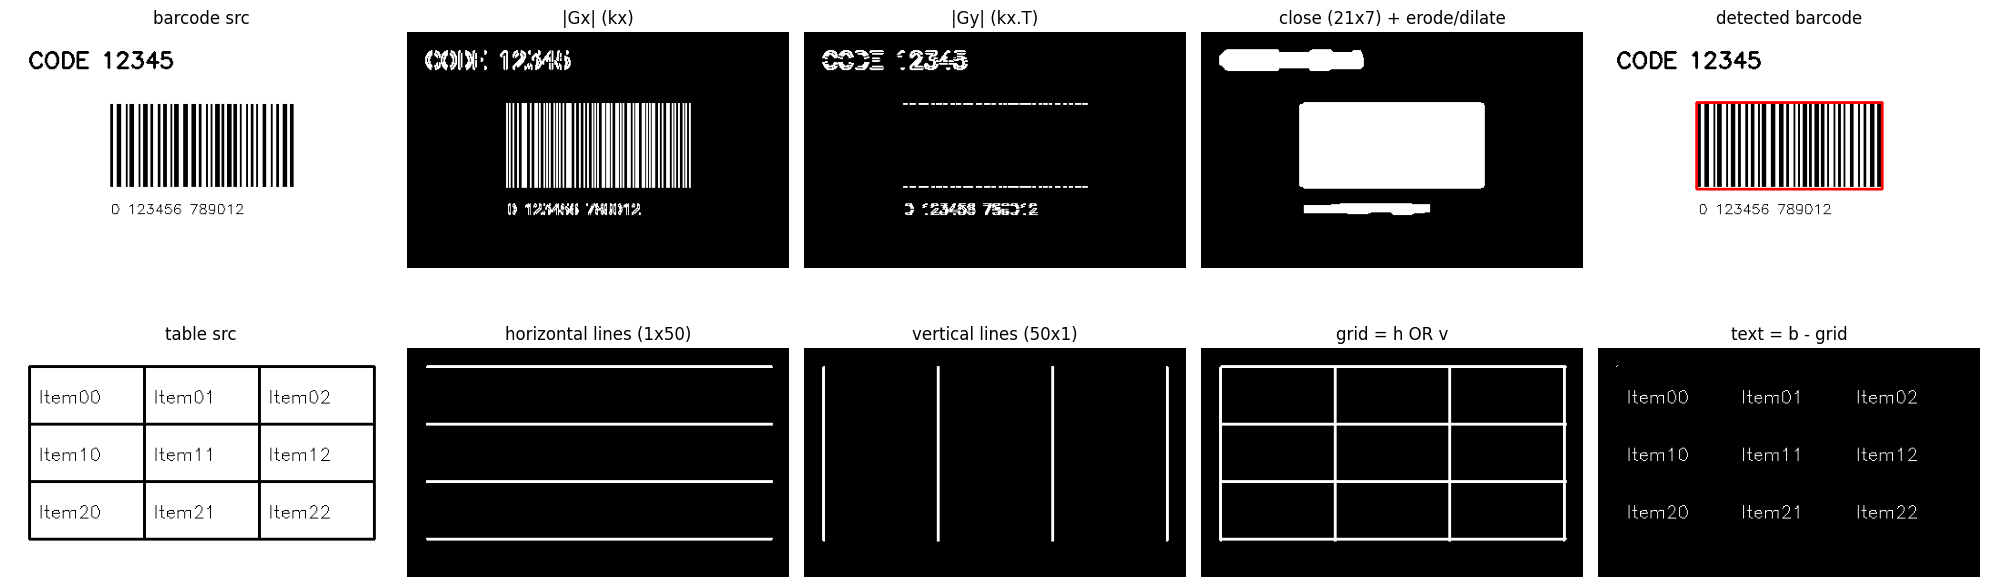

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =============== 準備:合成條碼圖與表格圖 ===============
# 條碼:垂直粗細不一的黑條 + 周圍文字(當干擾)
bar = np.full((260, 420), 255, np.uint8)
rng = np.random.default_rng(1)
x = 110
while x < 310:
    wd = int(rng.integers(2, 6))
    cv2.rectangle(bar, (x, 80), (x + wd - 1, 170), 0, -1)
    x += wd + int(rng.integers(2, 6))
cv2.putText(bar, "CODE 12345", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.8, 0, 2)
cv2.putText(bar, "0 123456 789012", (110, 200), cv2.FONT_HERSHEY_SIMPLEX, 0.5, 0, 1)

# 表格:3x3 格線 + 文字
tb = np.full((240, 400), 255, np.uint8)
for y in (20, 80, 140, 200):
    cv2.line(tb, (20, y), (380, y), 0, 2)
for xx in (20, 140, 260, 380):
    cv2.line(tb, (xx, 20), (xx, 200), 0, 2)
for r in range(3):
    for k in range(3):
        cv2.putText(tb, f"Item{r}{k}", (30 + k * 120, 58 + r * 60),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, 0, 1)

# =============== A. 條碼:自訂方向性核 ===============
kx = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]], np.float32)       # 偵測「左右」亮度變化 → 垂直邊
ky = kx.T                                      # 轉置 → 偵測「上下」變化 → 水平邊

gx = cv2.filter2D(bar, cv2.CV_32F, kx)
gy = cv2.filter2D(bar, cv2.CV_32F, ky)
grad = cv2.convertScaleAbs(np.abs(gx) - np.abs(gy))   # 水平梯度大、垂直梯度小 = 條碼

blur = cv2.blur(grad, (9, 9))
_, th = cv2.threshold(blur, 60, 255, cv2.THRESH_BINARY)

# 橫向長條形核:把一根根直條「橫向黏」成一個塊
close = cv2.morphologyEx(th, cv2.MORPH_CLOSE,
                         cv2.getStructuringElement(cv2.MORPH_RECT, (21, 7)))
close = cv2.erode(close, None, iterations=4)          # 去掉零碎雜訊
close = cv2.dilate(close, None, iterations=4)

cnts, _ = cv2.findContours(close, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
c = max(cnts, key=cv2.contourArea)
bx, by, bw, bh = cv2.boundingRect(c)
bar_show = cv2.cvtColor(bar, cv2.COLOR_GRAY2RGB)
cv2.rectangle(bar_show, (bx, by), (bx + bw, by + bh), (255, 0, 0), 2)

# =============== B. 表格:水平核 / 垂直核 ===============
_, b = cv2.threshold(cv2.bitwise_not(tb), 127, 255, cv2.THRESH_BINARY)  # 線 = 255

hk = np.ones((1, 50), np.uint8)    # 水平核:寬 50、高 1 → 只保留長橫線
vk = np.ones((50, 1), np.uint8)    # 垂直核:寬 1、高 50 → 只保留長直線

hlines = cv2.dilate(cv2.erode(b, hk), hk)      # 開運算 = 先侵蝕再膨脹
vlines = cv2.dilate(cv2.erode(b, vk), vk)
grid = cv2.bitwise_or(hlines, vlines)
text = cv2.subtract(b, grid)                    # 扣掉格線,只剩文字

# =============== 顯示 ===============
def show(ax, im, title):
    ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(2, 5, figsize=(20, 7))

show(axes[0, 0], bar,  "barcode src")
show(axes[0, 1], np.clip(np.abs(gx), 0, 255).astype(np.uint8), "|Gx| (kx)")
show(axes[0, 2], np.clip(np.abs(gy), 0, 255).astype(np.uint8), "|Gy| (kx.T)")
show(axes[0, 3], close, "close (21x7) + erode/dilate")
show(axes[0, 4], bar_show, "detected barcode")

show(axes[1, 0], tb,     "table src")
show(axes[1, 1], hlines, "horizontal lines (1x50)")
show(axes[1, 2], vlines, "vertical lines (50x1)")
show(axes[1, 3], grid,   "grid = h OR v")
show(axes[1, 4], text,   "text = b - grid")

plt.tight_layout()
plt.show()


# 🔲 2. 兩大基石運算 (Fundamental Operations)

## Dilate 膨脹（填補孔洞、橋接斷裂邊緣、物體擴張）

> 與侵蝕相反，與卷積核對應的原圖像的圖元值中`只要有一個是 1`，中心元素的圖元值就是 1。所以這個操作會增加圖像中的白色區域（前景）。一般在去雜訊時先用侵蝕再用膨脹。因為侵蝕在去掉白色雜訊的同時，也會使前景對像變小。所以我們再對他進行膨脹。這時雜訊已經被去除了，不會再回來了，但是前景還在並會增加。

> 膨脹也可以用來連接兩個分開的物體。其實，膨脹就是求區域性最大值的操作。按數學方面來說，膨脹或者侵蝕操作就是將影像（或影像的一部分割槽域，我們稱之為 A）與核（我們稱之為 B）進行卷積。

>核可以是任何的形狀和大小，它擁有一個單獨定義出來的參考點，我們稱其為錨點（anchorpoint）。多數情況下，核是一個小的中間帶有參考點和實心正方形或者圓盤，其實，我們可以把核視為模板或者掩碼。

>而膨脹就是求區域性最大值的操作，核B與圖形卷積，即計算核B覆蓋的區域的畫素點的最大值，並把這個最大值賦值給參考點指定的畫素。這樣就會使影像中的高亮區域逐漸增長。如下圖所示，這就是膨脹操作的初衷。<br>

In [ ]:
import cv2
import numpy as np
img=np.zeros((5,5),np.uint8)
img[2:3,1:4]=1
kernel = np.ones((3,1),np.uint8)
dilation = cv2.dilate(img,kernel)
print("img=\n",img)
print("kernel=\n",kernel)
print("dilation\n",dilation)

img=
 [[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]
kernel=
 [[1]
 [1]
 [1]]
dilation
 [[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


## Erosion 腐蝕 (腐蝕毛邊、消除小噪點、物體分離）
>### Erode 侵蝕 : 以 Kernel 中心點移動
> 卷積核沿著圖像滑動，如果與卷積核對應的原圖像的`所有圖元值與 Kernel 相同, 那麼中心元素就給 1，否則就變為零`。根據卷積核的大小靠近前景的所有圖元都會被侵蝕掉（變為0），所以`前景物體會變小`，整幅圖像的白色區域會減少。這對於`去除白色雜訊很有用`，也可以用來斷開兩個連在一塊的物體等。  

> cv2.erode(img, kernel=None, iterations =1)

> * img : 指需要侵蝕的圖
> * kernel : 指侵蝕操作的內核，默認是一個簡單的 3X3 全 1 的矩陣，我們也可以利用 getStructuringElement（）函數指明它的形狀
> * iterations : 指的是侵蝕次數，省略是默認為1

>在進行侵蝕和膨脹的講解之前，首先需要注意，侵蝕和膨脹是對白色部分（高亮部分）而言的，不是黑色部分。膨脹就是影像中的高亮部分進行膨脹，`領域擴張`，效果圖擁有比原圖更大的高亮區域。侵蝕就是原圖中的高亮部分被侵蝕，`領域被蠶食`，效果圖擁有比原圖更小的高亮區域


shape = (600, 800, 3)  dtype = uint8


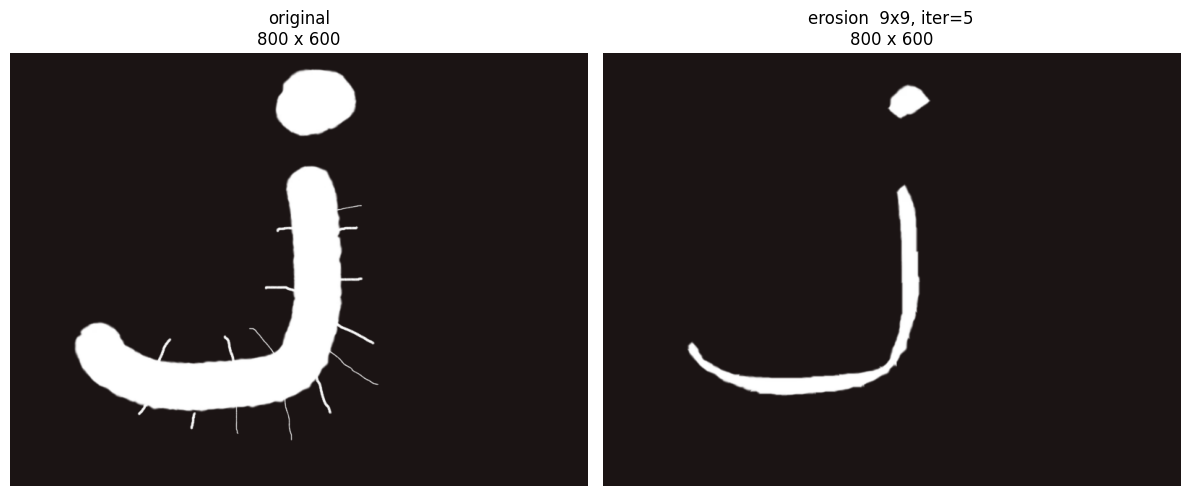

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀圖(IMREAD_UNCHANGED 可能得到 2D 灰階、3ch BGR、4ch BGRA)
o = cv2.imread("erode.bmp", cv2.IMREAD_UNCHANGED)
assert o is not None, "讀不到 erode.bmp,請確認路徑"

kernel = np.ones((9, 9), np.uint8)
erosion = cv2.erode(o, kernel, iterations=5)

print("shape =", o.shape, " dtype =", o.dtype)


# 2. 轉成 matplotlib 吃得下的格式
def to_display(im):
    if im.ndim == 2:                               # 灰階
        return im, "gray"
    if im.shape[2] == 4:                           # BGRA -> RGBA
        return cv2.cvtColor(im, cv2.COLOR_BGRA2RGBA), None
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB), None  # BGR -> RGB


# 3. 顯示
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, im, title in [(axes[0], o,       "original"),
                      (axes[1], erosion, "erosion  9x9, iter=5")]:
    disp, cmap = to_display(im)
    ax.imshow(disp, cmap=cmap)
    ax.set_title(f"{title}\n{im.shape[1]} x {im.shape[0]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 迭代次數 (iterations) 的影響

# 🔄 3. 複合形態學運算 (cv2.morphologyEx)

### Opening 開運算（先侵蝕後膨脹：去除孤立小白點）
開運算先進行腐蝕，再進行膨脹。
主要用來去除小物體，適合去除前景中的小噪點。

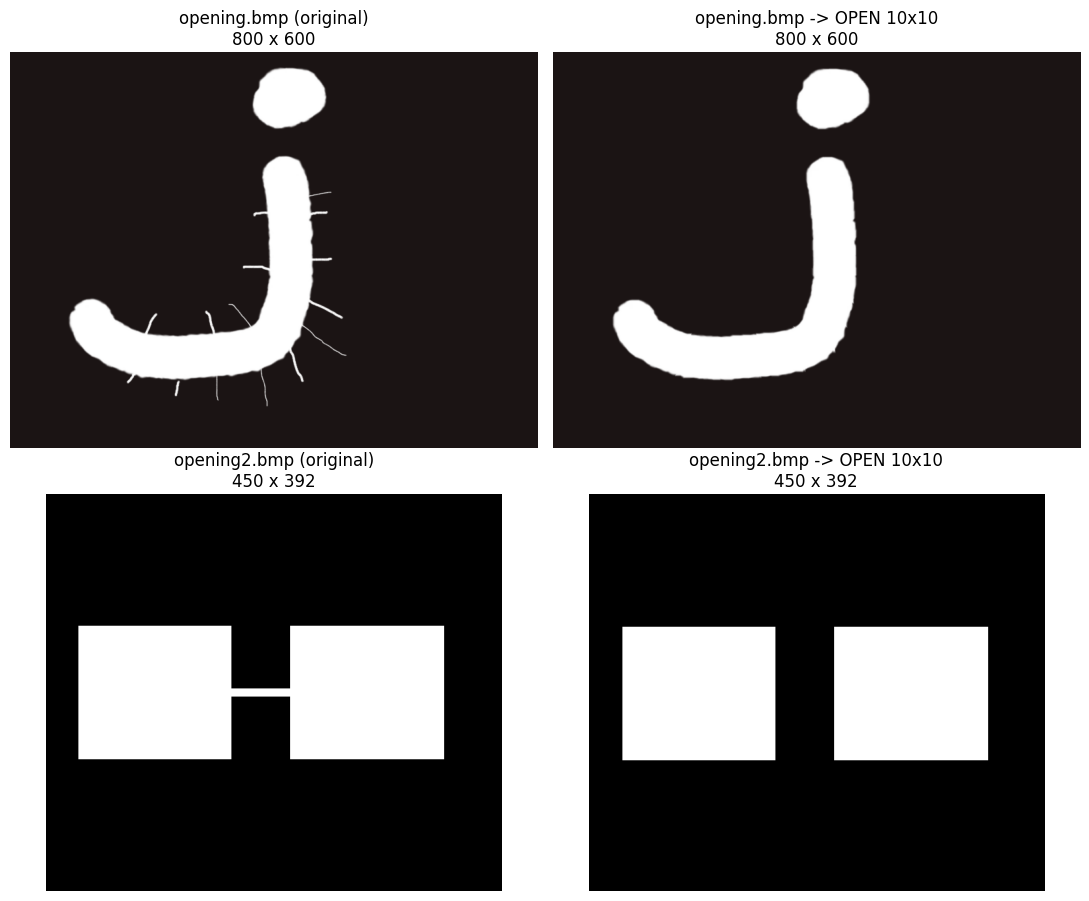

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀圖(預設為 3 通道 BGR)
img1 = cv2.imread("opening.bmp")
img2 = cv2.imread("opening2.bmp")
assert img1 is not None, "讀不到 opening.bmp,請確認路徑"
assert img2 is not None, "讀不到 opening2.bmp,請確認路徑"

# 2. 開運算(先侵蝕再膨脹):10x10 方形核
k = np.ones((10, 10), np.uint8)
r1 = cv2.morphologyEx(img1, cv2.MORPH_OPEN, k)
r2 = cv2.morphologyEx(img2, cv2.MORPH_OPEN, k)

# 3. BGR -> RGB(matplotlib 吃 RGB)
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

# 4. 顯示:每一列是「原圖 → 開運算後」
items = [("opening.bmp (original)",  img1),
         ("opening.bmp -> OPEN 10x10", r1),
         ("opening2.bmp (original)", img2),
         ("opening2.bmp -> OPEN 10x10", r2)]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (title, im) in zip(axes.ravel(), items):
    ax.imshow(rgb(im))
    ax.set_title(f"{title}\n{im.shape[1]} x {im.shape[0]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### Closing 閉運算（先膨脹後侵蝕：填平凹洞與閉合裂縫）
閉運算（Closing）：先進行膨脹，再進行腐蝕。
主要用來填補背景中的小孔洞，適合去除背景中的小噪點。

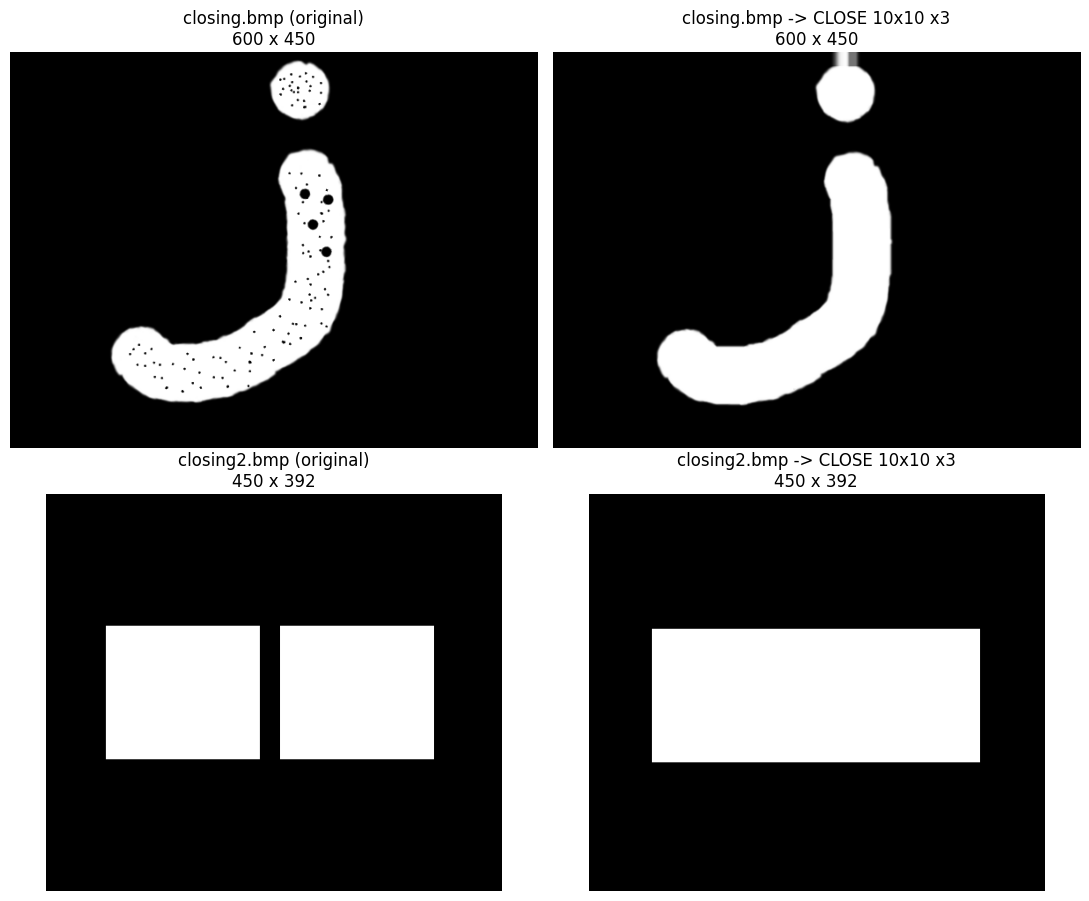

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀圖(預設為 3 通道 BGR)
img1 = cv2.imread("closing.bmp")
img2 = cv2.imread("closing2.bmp")
assert img1 is not None, "讀不到 closing.bmp,請確認路徑"
assert img2 is not None, "讀不到 closing2.bmp,請確認路徑"

# 2. 閉運算(先膨脹再侵蝕):10x10 方形核,重複 3 次
k = np.ones((10, 10), np.uint8)
r1 = cv2.morphologyEx(img1, cv2.MORPH_CLOSE, k, iterations=3)
r2 = cv2.morphologyEx(img2, cv2.MORPH_CLOSE, k, iterations=3)

# 3. BGR -> RGB(matplotlib 吃 RGB)
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

# 4. 顯示:每一列是「原圖 → 閉運算後」
items = [("closing.bmp (original)",       img1),
         ("closing.bmp -> CLOSE 10x10 x3", r1),
         ("closing2.bmp (original)",      img2),
         ("closing2.bmp -> CLOSE 10x10 x3", r2)]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (title, im) in zip(axes.ravel(), items):
    ax.imshow(rgb(im))
    ax.set_title(f"{title}\n{im.shape[1]} x {im.shape[0]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### Gradient 形態學梯度（膨脹 - 侵蝕：快速提取二值外邊界）
1. 核心重點
> * **運算公式：** `Gradient = Dilation (膨脹圖) - Erosion (侵蝕圖)`
> * **原理解析：** 「膨脹」會將物體邊界向外擴張一圈，「侵蝕」則將邊界向內收縮一圈；兩者相減即可抵消物體內部平坦區域，**只留下中空的邊緣輪廓**。
> * **視覺效果：** 取得前景物體的邊界，常用於輪廓提取與邊緣強化。Kernel 尺寸越大，計算出的輪廓線條越寬。

2. 數學定義
$\text{Gradient}(I) = (I \oplus K) - (I \ominus K)$
* $I$：輸入原影像 (Input Image)
* $K$：結構元素 (Structuring Element / Kernel)
* $I \oplus K$：膨脹運算 (Dilation)
* $I \ominus K$：侵蝕運算 (Erosion)

3. 三種形態學梯度對照（進階補充）

| 梯度類型 | 計算公式 | 邊緣位置與特性 |
| :--- | :--- | :--- |
| **基本梯度 (Basic Gradient)** | `膨脹圖 - 侵蝕圖` | 跨在真實邊界正中央（內外各佔一半），OpenCV `cv2.MORPH_GRADIENT` 預設採用此方式。 |
| **內部梯度 (Internal Gradient)** | `原圖 - 侵蝕圖` | 邊緣完全落在**物體內部**（向內描邊）。 |
| **外部梯度 (External Gradient)** | `膨脹圖 - 原圖` | 邊緣完全落在**物體外部**（向外描邊）。 |

兩種寫法相同 ? True


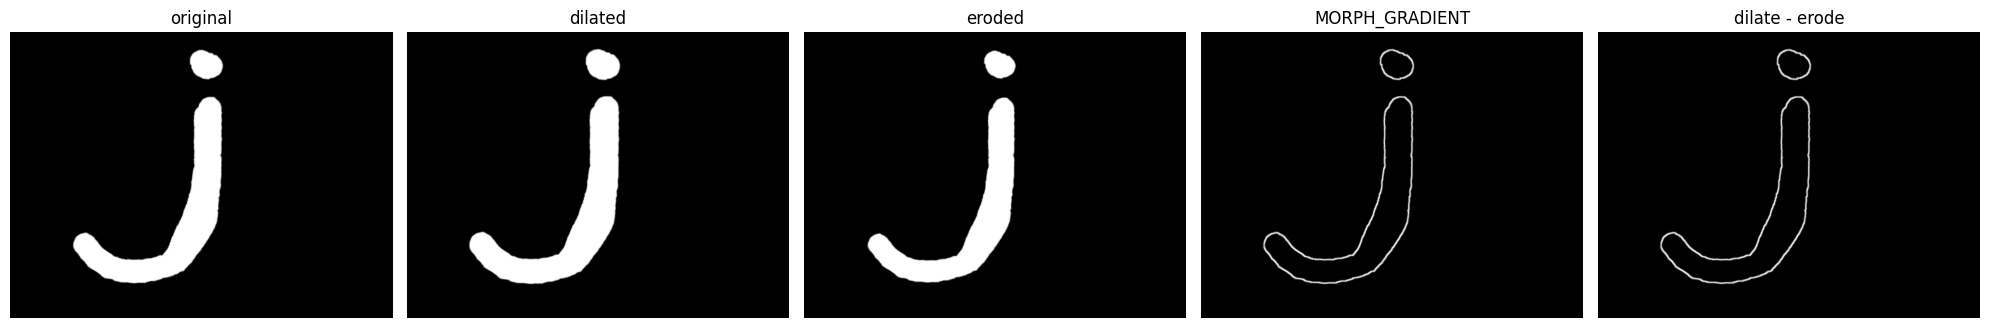

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀取影像(讀不到就用測試影像)
img = cv2.imread("gradient.bmp", cv2.IMREAD_GRAYSCALE)

if img is None:
    img = np.zeros((300, 300), np.uint8)
    cv2.circle(img, (150, 150), 80, 255, -1)
    img = cv2.GaussianBlur(img, (9, 9), 0)      # 做出漸層邊緣
    print("使用測試影像")

# 2. 結構元素:Kernel 大小決定邊緣線條的粗細
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# 3. 形態學梯度(= 膨脹 - 侵蝕,得到中空輪廓)
gradient = cv2.morphologyEx(img, cv2.MORPH_GRADIENT, kernel)

# 等價寫法
dilated   = cv2.dilate(img, kernel)
eroded    = cv2.erode(img, kernel)
gradient2 = cv2.subtract(dilated, eroded)

# 4. 驗證兩種寫法逐像素相同
print("兩種寫法相同 ?", bool(np.array_equal(gradient, gradient2)))

# 5. 顯示(灰階圖固定 vmin/vmax,避免 matplotlib 自動拉伸對比)
items = [("original", img),
         ("dilated", dilated),
         ("eroded", eroded),
         ("MORPH_GRADIENT", gradient),
         ("dilate - erode", gradient2)]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (title, im) in zip(axes, items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


MORPH_GRADIENT == d - e ? True


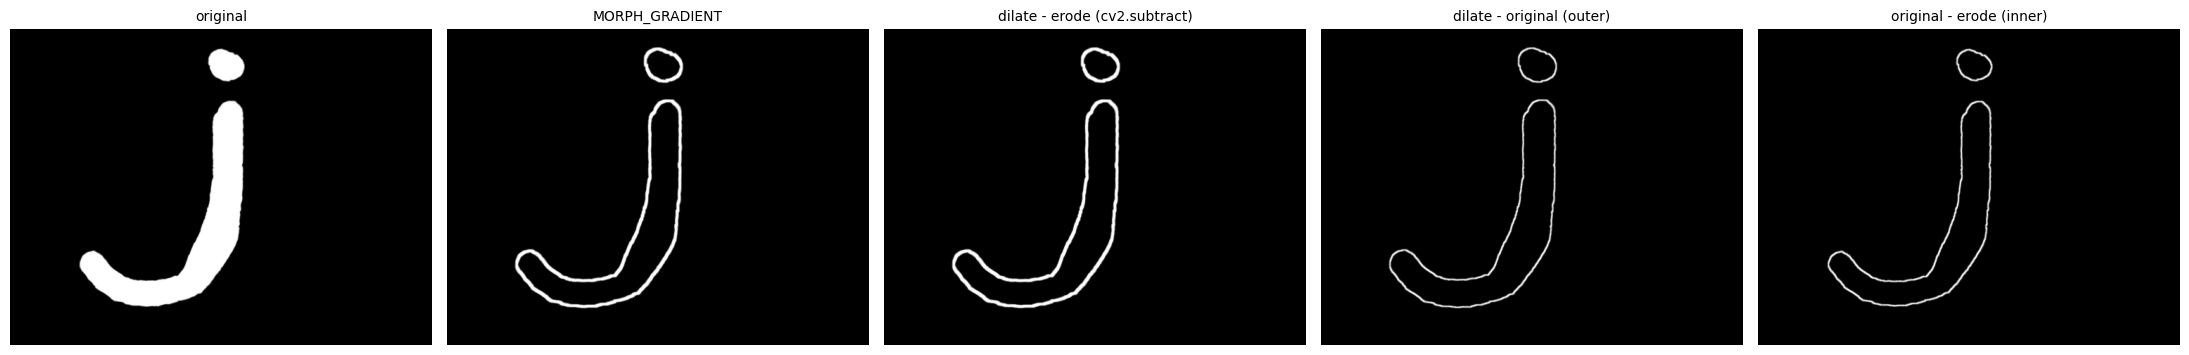

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀圖(預設為 3 通道 BGR)
o = cv2.imread("gradient.bmp")
assert o is not None, "讀不到 gradient.bmp,請確認路徑"

# 2. 核與運算
k = np.ones((5, 5), np.uint8)
ITER = 1                                          # try to add iteration:改成 2、3 看輪廓變粗

d = cv2.dilate(o, k, iterations=ITER)             # 膨脹
e = cv2.erode(o, k, iterations=ITER)              # 侵蝕
r = cv2.morphologyEx(o, cv2.MORPH_GRADIENT, k, iterations=ITER)   # 形態學梯度

de = cv2.subtract(d, e)                           # 膨脹 - 侵蝕 = 形態學梯度
do = cv2.subtract(d, o)                           # 膨脹 - 原圖 = 外部梯度
oe = cv2.subtract(o, e)                           # 原圖 - 侵蝕 = 內部梯度

print("MORPH_GRADIENT == d - e ?", bool(np.array_equal(r, de)))

# 3. BGR -> RGB(matplotlib 吃 RGB)
rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

# 4. 顯示
items = [("original",                     o),
         ("MORPH_GRADIENT",               r),
         ("dilate - erode (cv2.subtract)", de),
         ("dilate - original (outer)",    do),
         ("original - erode (inner)",     oe)]

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (title, im) in zip(axes, items):
    ax.imshow(rgb(im))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()


### Top-Hat 頂帽 / 禮帽運算（原圖 - 開運算：提取比背景亮的微小細節）

1. 核心重點
> * **運算公式：** `Top-Hat = 原圖 - Open (開運算圖)`
> * **取得雜訊資訊：** 分離出原影像中被開運算抹除的細小白色雜訊或亮斑。
> * **強化高亮邊緣：** 取得比原影像邊緣更 `亮` 的細微邊緣與局部突刺。
> * **突顯亮部目標：** 顯示出原圖去除掉的白色部分，主要用於**突顯暗背景中的微小亮物體**，以及消除大面積不均勻背景光照。

2. 數學定義
$$\text{Top-Hat}(I) = I - (I \circ K)$$
* $I$：輸入原影像 (Input Image)
* $K$：結構元素 (Structuring Element / Kernel)
* $I \circ K$：對原圖進行開運算（先侵蝕、後膨脹）

o1: (600, 800, 3) uint8
o2: (512, 512, 3) uint8
r1 == im - open(im) ? True
r2 == im - open(im) ? True


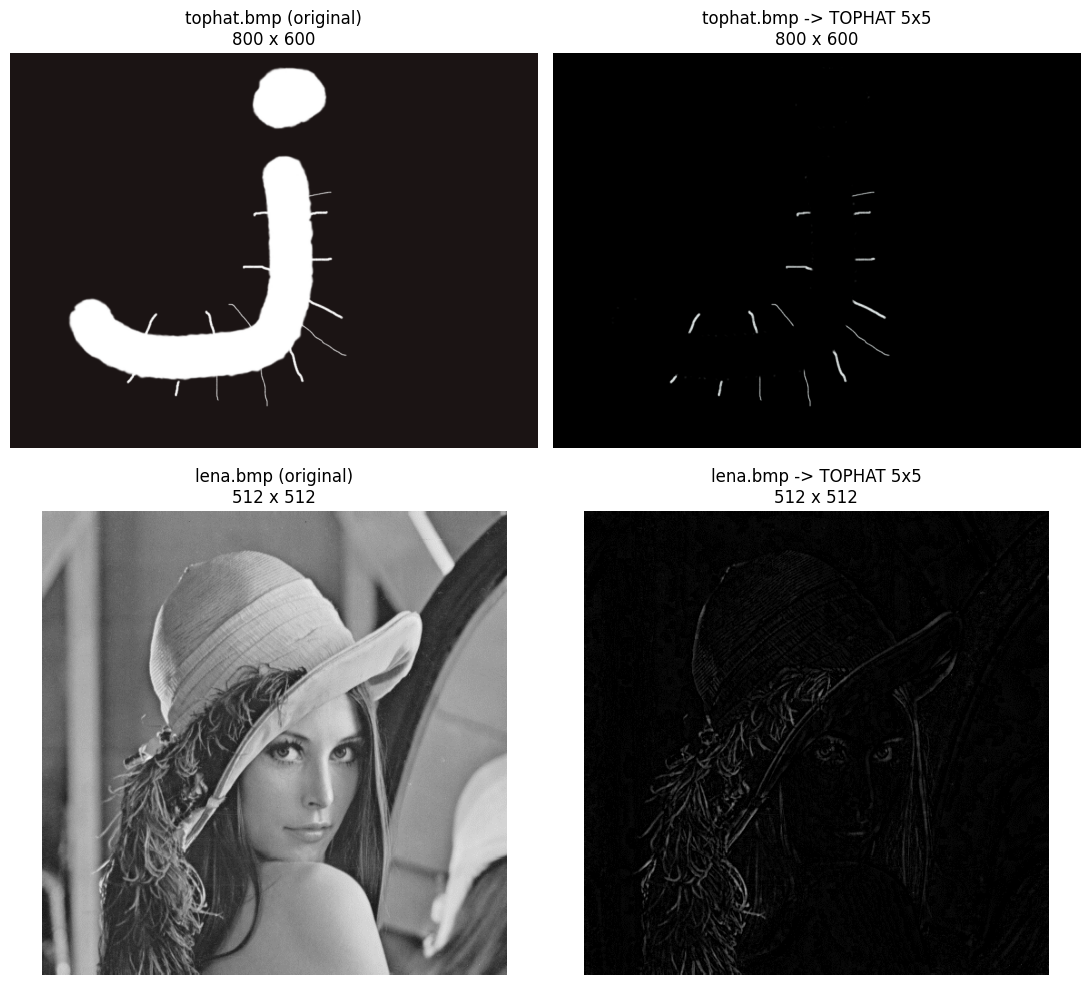

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀圖(IMREAD_UNCHANGED 可能得到 2D 灰階、3ch BGR 或 4ch BGRA)
o1 = cv2.imread("tophat.bmp", cv2.IMREAD_UNCHANGED)
o2 = cv2.imread("lena.bmp",   cv2.IMREAD_UNCHANGED)
assert o1 is not None, "讀不到 tophat.bmp,請確認路徑"
assert o2 is not None, "讀不到 lena.bmp,請確認路徑"

print("o1:", o1.shape, o1.dtype)
print("o2:", o2.shape, o2.dtype)

# 2. 頂帽運算 = 原圖 - 開運算(取出比核小的亮細節)
k  = np.ones((5, 5), np.uint8)
r1 = cv2.morphologyEx(o1, cv2.MORPH_TOPHAT, k)
r2 = cv2.morphologyEx(o2, cv2.MORPH_TOPHAT, k)

# 3. 等價驗證(只在單通道時最直觀,多通道也會逐通道成立)
def tophat_manual(im, kernel):
    return cv2.subtract(im, cv2.morphologyEx(im, cv2.MORPH_OPEN, kernel))

print("r1 == im - open(im) ?", bool(np.array_equal(r1, tophat_manual(o1, k))))
print("r2 == im - open(im) ?", bool(np.array_equal(r2, tophat_manual(o2, k))))


# 4. 轉成 matplotlib 可顯示的格式
def to_display(im):
    if im.ndim == 2:                                   # 灰階
        return im, "gray"
    if im.shape[2] == 4:                               # BGRA -> RGBA
        return cv2.cvtColor(im, cv2.COLOR_BGRA2RGBA), None
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB), None   # BGR -> RGB


# 5. 顯示:左欄原圖,右欄頂帽結果
items = [("tophat.bmp (original)",             o1),
         ("tophat.bmp -> TOPHAT 5x5",          r1),
         ("lena.bmp (original)",               o2),
         ("lena.bmp -> TOPHAT 5x5",            r2)]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (title, im) in zip(axes.ravel(), items):
    disp, cmap = to_display(im)
    ax.imshow(disp, cmap=cmap, vmin=None if cmap is None else 0,
              vmax=None if cmap is None else 255)
    hh, ww = im.shape[:2]
    ax.set_title(f"{title}\n{ww} x {hh}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### Black-Hat 黑帽運算（閉運算 - 原圖：提取比背景暗的微小細節）

1. 核心重點
> * **運算公式：** `Black-Hat = Close (閉運算圖) - 原圖`
> * **提取內部小孔：** 取得原影像內部的小孔洞，或前景物體中的小黑點、暗斑。
> * **強化暗部邊緣：** 取得比原影像邊緣更 `暗` 的細微邊緣與輪廓凹陷。
> * **突顯暗部目標：** 顯示出閉運算所填平的黑色部分，主要用於**突顯亮背景中的微小暗物體**（如表面裂痕、血管暗影、文字筆畫）。

2. 數學定義
$\text{Black-Hat}(I) = (I \bullet K) - I$
* $I$：輸入原影像 (Input Image)
* $K$：結構元素 (Structuring Element / Kernel)
* $I \bullet K$：對原圖進行閉運算（先膨脹、後侵蝕，會填補小黑洞使灰階值升高）

o1: (450, 600, 3) uint8
o2: (512, 512, 3) uint8
r1 == close(im) - im ? True
r2 == close(im) - im ? True


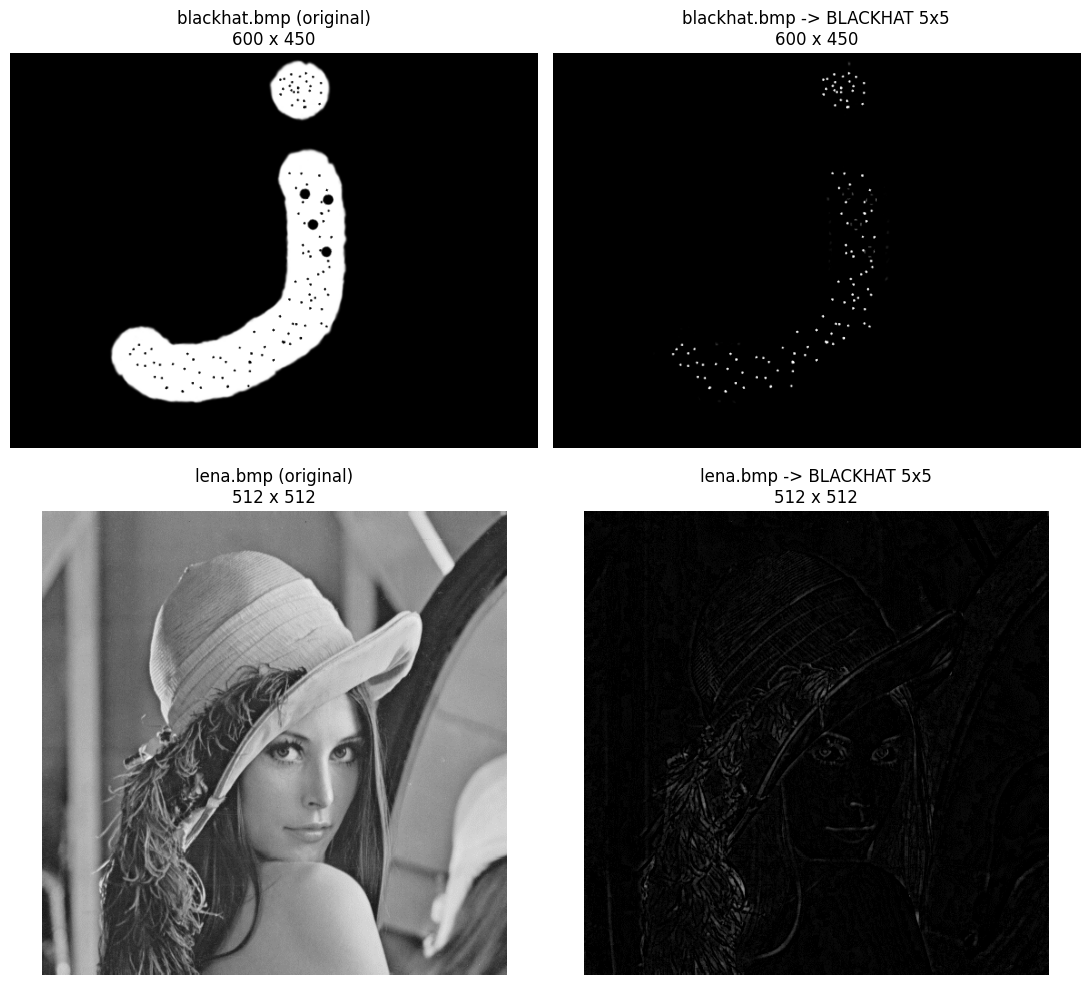

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 讀圖(IMREAD_UNCHANGED 可能得到 2D 灰階、3ch BGR 或 4ch BGRA)
o1 = cv2.imread("blackhat.bmp", cv2.IMREAD_UNCHANGED)
o2 = cv2.imread("lena.bmp",     cv2.IMREAD_UNCHANGED)
assert o1 is not None, "讀不到 blackhat.bmp,請確認路徑"
assert o2 is not None, "讀不到 lena.bmp,請確認路徑"

print("o1:", o1.shape, o1.dtype)
print("o2:", o2.shape, o2.dtype)

# 2. 黑帽運算 = 閉運算 - 原圖(取出比核小的暗細節)
k  = np.ones((5, 5), np.uint8)
r1 = cv2.morphologyEx(o1, cv2.MORPH_BLACKHAT, k)
r2 = cv2.morphologyEx(o2, cv2.MORPH_BLACKHAT, k)

# 3. 等價驗證
def blackhat_manual(im, kernel):
    return cv2.subtract(cv2.morphologyEx(im, cv2.MORPH_CLOSE, kernel), im)

print("r1 == close(im) - im ?", bool(np.array_equal(r1, blackhat_manual(o1, k))))
print("r2 == close(im) - im ?", bool(np.array_equal(r2, blackhat_manual(o2, k))))


# 4. 轉成 matplotlib 可顯示的格式
def to_display(im):
    if im.ndim == 2:                                   # 灰階
        return im, "gray"
    if im.shape[2] == 4:                               # BGRA -> RGBA
        return cv2.cvtColor(im, cv2.COLOR_BGRA2RGBA), None
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB), None   # BGR -> RGB


# 5. 顯示:每一列是「原圖 → 黑帽結果」
items = [("blackhat.bmp (original)",    o1),
         ("blackhat.bmp -> BLACKHAT 5x5", r1),
         ("lena.bmp (original)",        o2),
         ("lena.bmp -> BLACKHAT 5x5",   r2)]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (title, im) in zip(axes.ravel(), items):
    disp, cmap = to_display(im)
    if cmap == "gray":
        ax.imshow(disp, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(disp)
    hh, ww = im.shape[:2]
    ax.set_title(f"{title}\n{ww} x {hh}")
    ax.axis("off")

plt.tight_layout()
plt.show()


#### 禮帽運算 & 黑帽運算
| 運算名稱 | OpenCV 參數 | 運算公式 | 提取目標 | 典型應用場景 |
| :--- | :--- | :--- | :--- | :--- |
| **禮帽運算 (Top-Hat)** | `cv2.MORPH_TOPHAT` | `原圖 - 開運算圖` | 比 Kernel 小的 **`亮部`** 細節 | 提取白色雜訊、暗背景中的亮物體、校正不均勻背景光 |
| **黑帽運算 (Black-Hat)** | `cv2.MORPH_BLACKHAT` | `閉運算圖 - 原圖` | 比 Kernel 小的 **`暗部`** 細節 | 提取黑色孔洞、亮背景中的暗物體、檢測表面暗裂紋 |

## Summary  
| 中文名    | 英文名 | api | 原理 | 個人理解 |
|:--------:|:------:|:---:|:----:|:--------:|
|  侵蝕    | erode             | erosion = cv2.erode(src=girl_pic, kernel=kernel) | 在窗中，只要含有０，則窗內全變為０，可以去淺色噪點	| 淺色成分被侵蝕 |
|  膨脹    | dilate            | dilation = cv2.dilate(src=girl_pic, kernel=kernel) | 在窗中，只要含有１，則窗內全變為１，可以增加淺色成分 | 淺色成分得膨脹 |
| 開運算   | morphology-open   | opening = cv2.morphologyEx(girl_pic, cv2.MORPH_OPEN, kernel) | 先侵蝕，後膨脹，去白噪點 | 先合再開，對淺色成分不利 |
| 閉運算   | morphology-close  | closing = cv2.morphologyEx(girl_pic, cv2.MORPH_CLOSE, kernel) | 先膨脹，後侵蝕，去黑噪點 | 先開再合，淺色成分得勢 |
|形態學梯度|morphology-grandient|gradient = cv2.morphologyEx(girl_pic, cv2.MORPH_GRADIENT, kernel)|一幅影像侵蝕與膨脹的區別，可以得到輪廓|數值上解釋為：膨脹減去侵蝕|
| 禮帽     | tophat             |	tophat = cv2.morphologyEx(girl_pic, cv2.MORPH_TOPHAT, kernel) |	原影像減去開運算的差 | 數值上解釋為：原影像減去開運算 |
| 黑帽     | blackhat           | blackhat = cv2.morphologyEx(girl_pic, cv2.MORPH_BLACKHAT, kernel) | 閉運算減去原影像的差 | 數值上解釋為：閉運算減去原影像 |

# 🎯 4. 進階形態學技術 (Advanced Morphology)

## cv2.connectedComponents

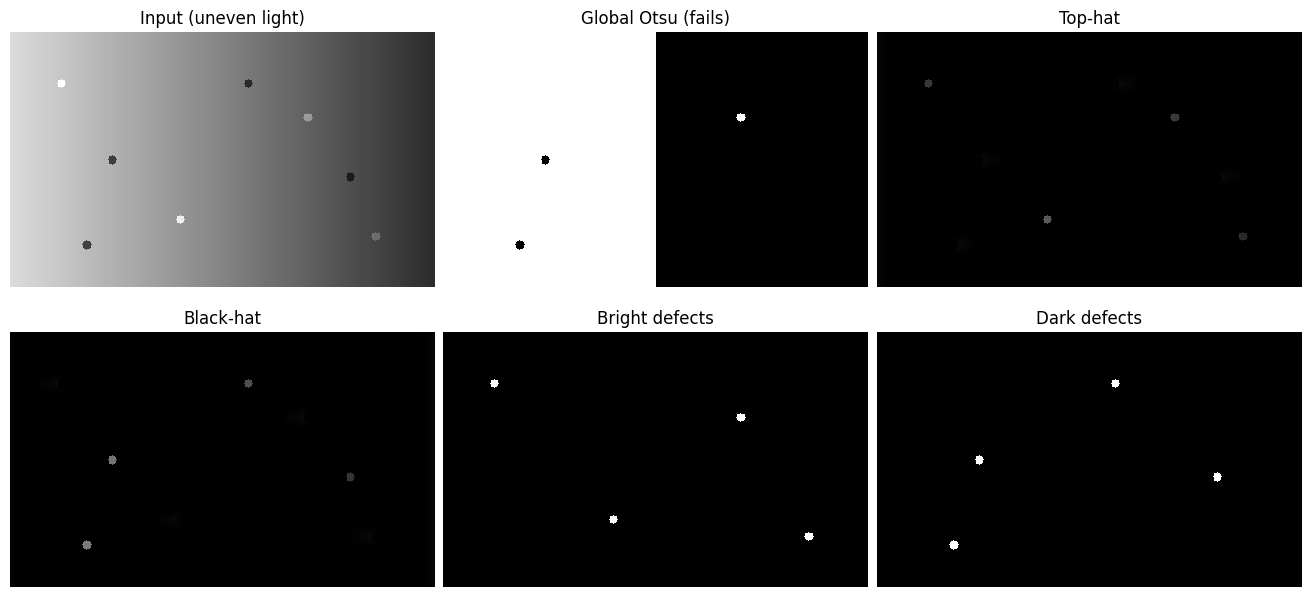

bright defects: 4 (truth 4), dark defects: 4 (truth 4)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 造圖：亮度由左到右變暗 + 亮點 + 暗點（乘性瑕疵）
h, w = 300, 500
yy, xx = np.mgrid[0:h, 0:w]
light = 1.0 - 0.8 * xx / w                      # 不均勻光照
R = np.ones((h, w), np.float32)
for x, y in [(60, 60), (200, 220), (350, 100), (430, 240)]:
    cv2.circle(R, (x, y), 5, 1.6, -1)           # 亮點
for x, y in [(120, 150), (280, 60), (400, 170), (90, 250)]:
    cv2.circle(R, (x, y), 5, 0.35, -1)          # 暗點
gray = np.clip(220 * light * R, 0, 255).astype(np.uint8)
# 用自己的圖: gray = cv2.imread("your.png", cv2.IMREAD_GRAYSCALE)

# 2. 頂帽 / 黑帽（SE 要比瑕疵大，這裡瑕疵直徑約 10 → 取 31）
k = 31
se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
pad = k // 2
g = cv2.copyMakeBorder(gray, pad, pad, pad, pad, cv2.BORDER_REFLECT)   # 避免邊緣失真
tophat   = cv2.morphologyEx(g, cv2.MORPH_TOPHAT,   se)[pad:-pad, pad:-pad]
blackhat = cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, se)[pad:-pad, pad:-pad]

# 3. 閾值
_, bright = cv2.threshold(tophat,   0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
_, dark   = cv2.threshold(blackhat, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
_, naive  = cv2.threshold(gray,     0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)  # 對照：全域 Otsu

# 4. 顯示
imgs = [(gray, "Input (uneven light)"), (naive, "Global Otsu (fails)"),
        (tophat, "Top-hat"), (blackhat, "Black-hat"),
        (bright, "Bright defects"), (dark, "Dark defects")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
for ax, (im, t) in zip(axes.ravel(), imgs):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255, interpolation="nearest")  # 固定色階
    ax.set_title(t); ax.axis("off")
plt.savefig("simple.png", dpi=130)
plt.show()

n1 = cv2.connectedComponents(bright)[0] - 1
n2 = cv2.connectedComponents(dark)[0] - 1
print(f"bright defects: {n1} (truth 4), dark defects: {n2} (truth 4)")


## cv2.connectedComponentsWithStats

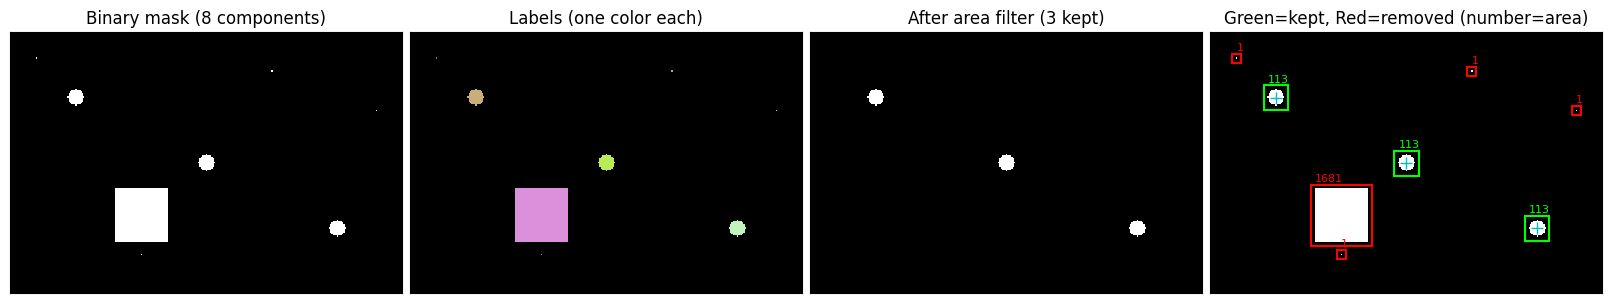

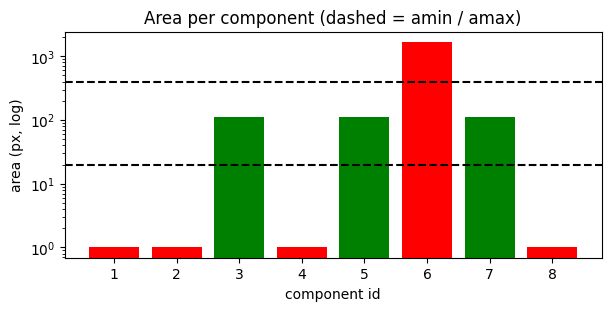

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 1. 造二值圖：3 個真目標 + 4 個雜訊 + 1 個過大塊
mask = np.zeros((200, 300), np.uint8)
for x, y in [(50, 50), (150, 100), (250, 150)]:
    cv2.circle(mask, (x, y), 6, 255, -1)
for x, y in [(20, 20), (100, 170), (200, 30), (280, 60)]:
    mask[y, x] = 255
cv2.rectangle(mask, (80, 120), (120, 160), 255, -1)
# 用自己的圖: _, mask = cv2.threshold(tophat, thr, 255, cv2.THRESH_BINARY)

# 2. 連通元件 + 面積過濾
n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)
area = stats[:, cv2.CC_STAT_AREA]
keep = (area >= 20) & (area <= 400)
keep[0] = False                                   # 背景
result = keep[labels].astype(np.uint8) * 255

# 3. 標籤上色：每個元件一種顏色，背景為黑
rng = np.random.default_rng(1)
palette = rng.integers(60, 255, (n, 3), dtype=np.uint8)
palette[0] = 0
label_rgb = palette[labels]                       # 同樣是查表

# 4. 四格圖
fig, axes = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

axes[0].imshow(mask, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].set_title(f"Binary mask ({n-1} components)")

axes[1].imshow(label_rgb, interpolation="nearest")
axes[1].set_title("Labels (one color each)")

axes[2].imshow(result, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[2].set_title(f"After area filter ({int(keep.sum())} kept)")

axes[3].imshow(mask, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
for i in range(1, n):
    x, y, w, h, a = stats[i]
    c = "lime" if keep[i] else "red"
    axes[3].add_patch(Rectangle((x - 3.5, y - 3.5), w + 6, h + 6, fill=False, ec=c, lw=1.5))
    axes[3].text(x, y - 6, f"{a}", color=c, fontsize=8)
    if keep[i]:
        axes[3].plot(*centroids[i], "c+", ms=8)
axes[3].set_title("Green=kept, Red=removed (number=area)")

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

# 5. 面積分布圖：看閾值切在哪裡
fig2, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.bar(range(1, n), area[1:], color=np.where(keep[1:], "green", "red"))
ax.axhline(20, ls="--", c="k"); ax.axhline(400, ls="--", c="k")
ax.set_yscale("log"); ax.set_xlabel("component id"); ax.set_ylabel("area (px, log)")
ax.set_title("Area per component (dashed = amin / amax)")
plt.show()
